# Carbon bombs: potential emissions figures (Tasks 5 and 6)

This notebook completes Tasks 5 and 6 of Environmental Programming Assignment 2. Task 5 ranks projects by their best-estimate potential CO2 emissions, displays the 20 largest projects, distinguishes countries by colour and fuel types by hatch, and shows the low-to-high estimate range as error bars. Task 6 compares cumulative best-estimate potential emissions by country and by fuel type.

The notebook uses the preprocessed `Data/ds_carbon_bombs.pkl` xarray Dataset made in Task 4. In that Dataset, `potential_emissions` has an `estimate` coordinate with `best`, `low`, and `high` entries. The source metadata defines the lower and upper values as the 2.5th and 97.5th percentile estimates. The totals in Task 6 are sums of the project-level `best` values; they are descriptive sums, not combined uncertainty intervals.

The dataset has project names, countries, and fuel types, but no project latitude/longitude coordinates. A project-location map would therefore require a separate, validated location dataset and is not inferred from country names here.

References: Kjell Kuehne et al. (2022), “Carbon Bombs” - Mapping key fossil fuel projects, *Energy Policy*, 166, 112950; Amaury Laridon et al. (2026, in prep.), updated carbon-bomb dataset and emissions framework. The estimates shown here are potential emissions from combustion of remaining reserves; they are not a forecast that all reserves will necessarily be extracted and burned.

## Step 1 - Load and inspect the prepared dataset

The helper module lives in `scripts/` and also contains the validation and plotting functions. The path search lets this notebook work when Jupyter is started from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

project_root = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "Data" / "ds_carbon_bombs.pkl").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not find Data/ds_carbon_bombs.pkl from the current directory or its parents."
    )
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.carbon_bombs_analysis import (
    carbon_bombs_to_frame,
    load_carbon_bombs_dataset,
    plot_country_totals,
    plot_fuel_totals,
    plot_top_20,
)

dataset = load_carbon_bombs_dataset(project_root / "Data" / "ds_carbon_bombs.pkl")
display(dataset)
projects = carbon_bombs_to_frame(dataset)
display(projects.head())

<xarray.Dataset> Size: 24kB
Dimensions:                 (name: 425, estimate: 3)
Coordinates:
  * name                    (name) object 3kB 'Tannezuft Shale' ... 'Sengwe C...
    country                 (name) object 3kB 'Algeria' 'Algeria' ... 'Zimbabwe'
    fuel                    (name) object 3kB 'Oil&Gas' 'Oil&Gas' ... 'Coal'
    project_id              (name) int64 3kB 1 2 3 4 5 6 ... 421 422 423 424 425
  * estimate                (estimate) <U4 48B 'best' 'low' 'high'
Data variables:
    potential_emissions     (name, estimate) float64 10kB 2.1 2.02 ... 1.35
    new                     (name) int8 425B 1 0 0 0 0 1 0 0 ... 0 1 1 1 1 0 1 0
    total                   float64 8B 923.9
    total_oil_and_gas       float64 8B 566.5
    total_coal              float64 8B 357.4
    total_new_carbon_bombs  float64 8B 293.0
Attributes:
    title:    Carbon bombs: potential CO2 emissions of the 425 largest fossil...
    source:   Laridon et al. (2026, in prep.) update of Kühne et al. (2022), ...
    note:     Totals are sums of best estimates. Low/high = 2.5th/97.5th perc...

,name,country,fuel,best,low,high
0,Tannezuft Shale,Algeria,Oil&Gas,2.100385,2.020170,2.185912
1,Hassi R'Mel (Domestic),Algeria,Oil&Gas,1.881471,1.815169,1.960945
2,Hassi Messaoud,Algeria,Oil&Gas,1.153444,1.117861,1.189111
3,Vaca Muerta Shale,Argentina,Oil&Gas,5.002366,4.896001,5.109565
4,Red Hill Coal Project,Australia,Coal,4.333640,4.311972,4.355308


In [2]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install xarray


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Task 5 - Plot the 20 largest projects

Projects are ranked by `best`, the central estimate, rather than by averaging the three estimates. The error bars are asymmetric: the lower length is `best - low` and the upper length is `high - best`. This accurately preserves the uncertainty range even when the best estimate is not exactly halfway between the endpoints. Country colours and fuel hatches have separate legends so the two encodings can be read independently.

The function saves a 300-dpi image to `figures/top_20_carbon_bombs.png` and returns the selected projects as a table.

,name,country,fuel,best,low,high
0,Permian Delaware Tight,United States,Oil&Gas,23.213425,22.676132,23.768128
1,Marcellus Shale,United States,Oil&Gas,23.022750,22.528469,23.532098
2,Ghawar Uthmaniyah,Saudi-Arabia,Oil&Gas,17.807717,17.175736,18.455981
3,Tavan Tolgoi Coal Mine,Mongolia,Coal,15.625370,14.419606,16.682477
4,Permian Midland Tight,United States,Oil&Gas,13.822325,13.518651,14.135439
5,Haynesville/Bossier Shale,United States,Oil&Gas,11.505439,11.373274,11.638580
6,Safaniya,Saudi-Arabia,Oil&Gas,11.330589,10.990319,11.671537
7,Montney Play,Canada,Oil&Gas,10.486196,10.195959,10.836906
8,North Field,Qatar,Oil&Gas,9.559376,9.127577,10.054197
9,Bovanenkovo Zone (Yamal Megaproject),Russian Federation,Oil&Gas,8.976883,8.889640,9.108712


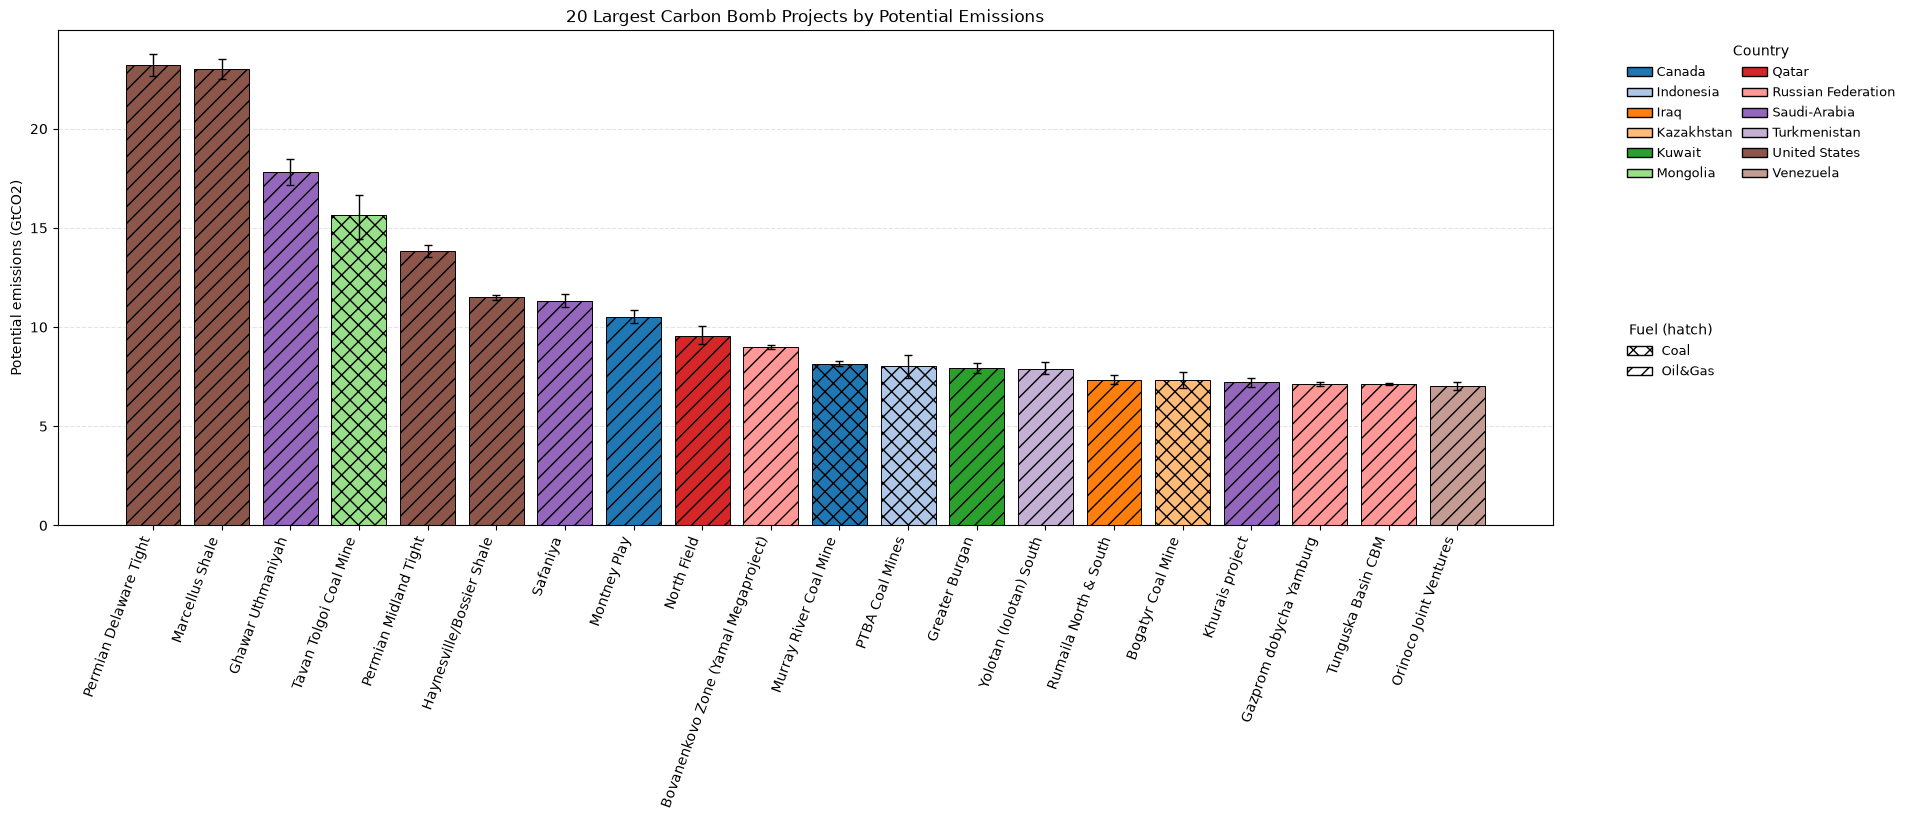

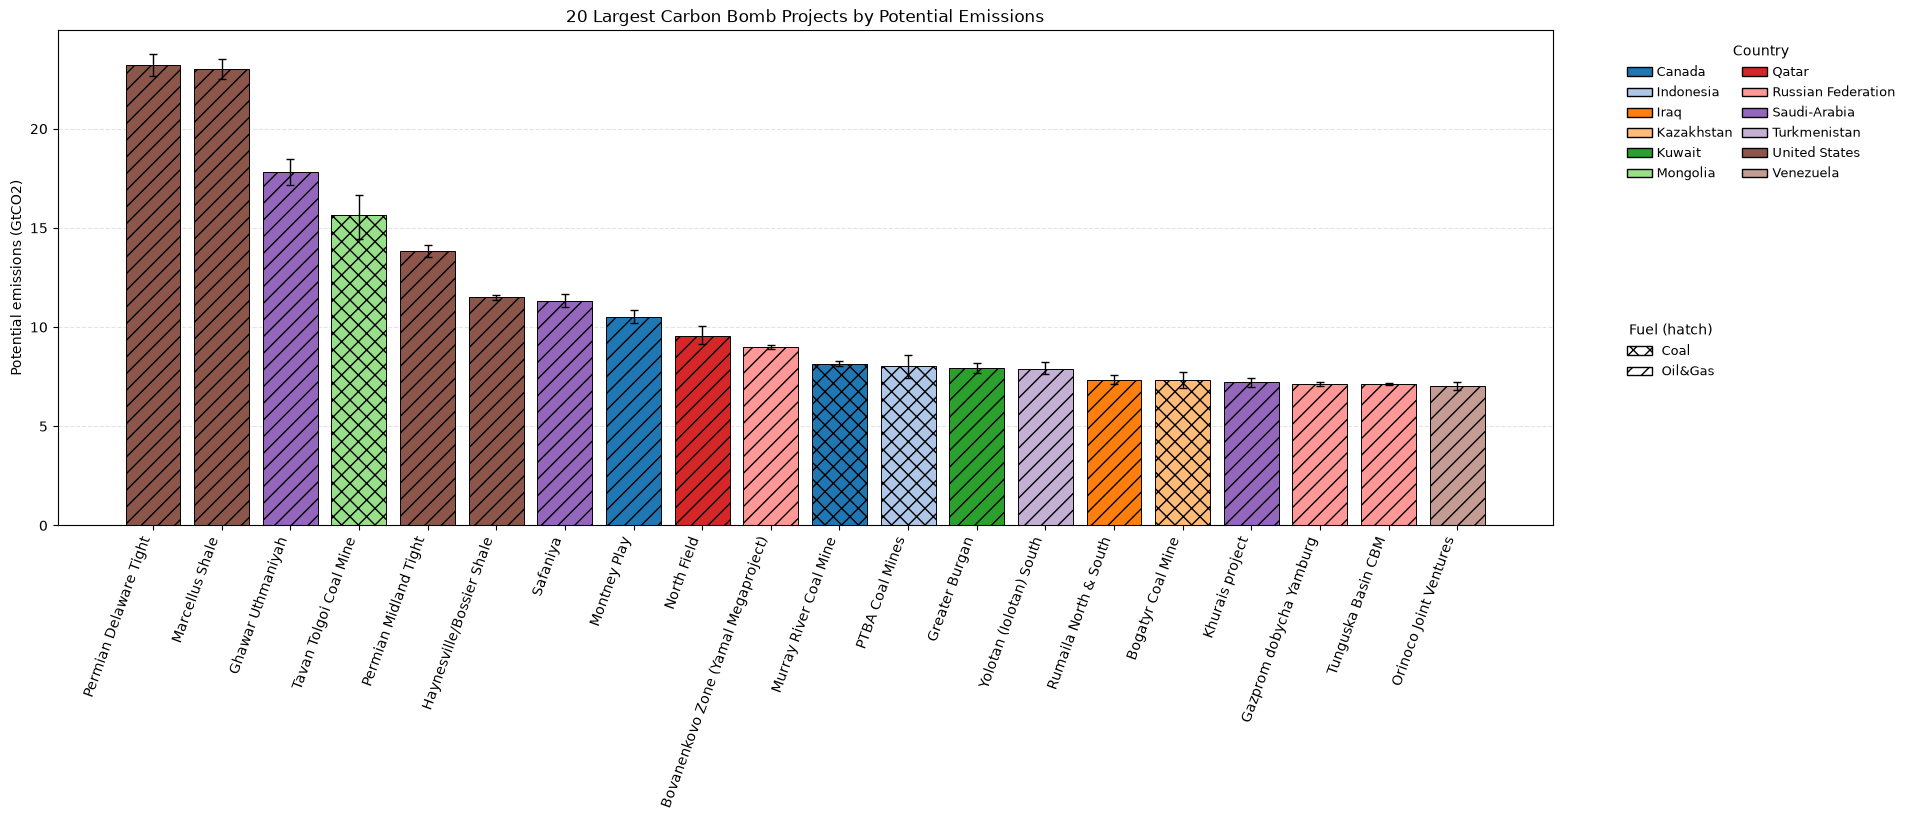

In [4]:
top_20_figure, top_20_axes, top_20_projects = plot_top_20(
    dataset,
    output_path=project_root / "figures" / "top_20_carbon_bombs.png",
)
display(top_20_projects[["name", "country", "fuel", "best", "low", "high"]])
display(top_20_figure)

In [5]:
%pip install matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### How to read the Task 5 figure

Each bar height is the project's best estimate in GtCO2. Its whiskers extend down to the low estimate and up to the high estimate. The colour identifies the project country, while the bar hatch identifies its fuel type. The projects are shown from largest to smaller best estimates. A long whisker indicates a wider estimate range, not a probability that the project will emit that amount.

## Task 6 - Compare cumulative potential emissions by country

This chart groups projects by their country coordinate and sums their `best` estimates. Only the 15 countries with the largest sums are displayed, for readability. The number beside each bar is the summed emissions in GtCO2. Project counts are also included in the returned table, because a large national total can result from many projects, a few very large projects, or both.

,country,total_best,project_count
0,China,187.264861,141
1,United States,125.343483,28
2,Saudi-Arabia,98.766491,23
3,Russian Federation,97.826301,41
4,Australia,47.355885,23
5,Qatar,35.802384,13
6,Canada,32.862301,12
7,Iraq,25.951105,11
8,Brazil,23.214251,10
9,United Arab Emirates,21.426250,7


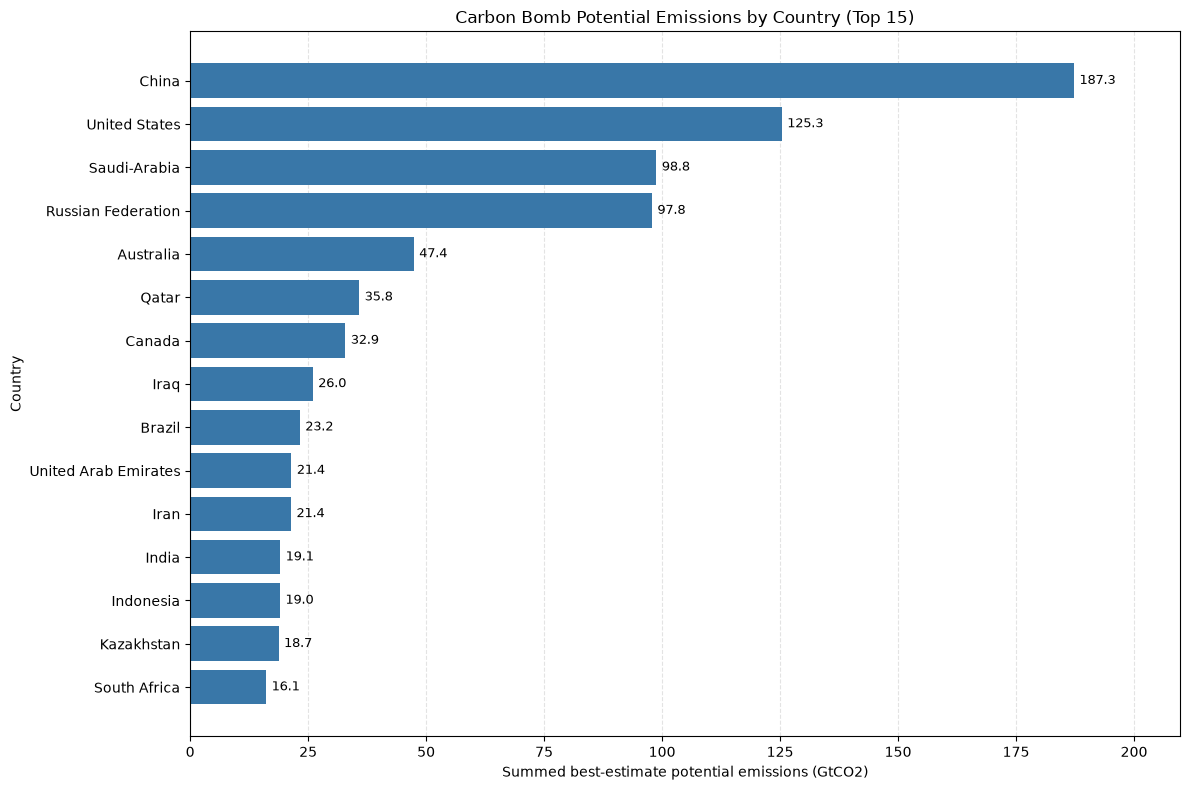

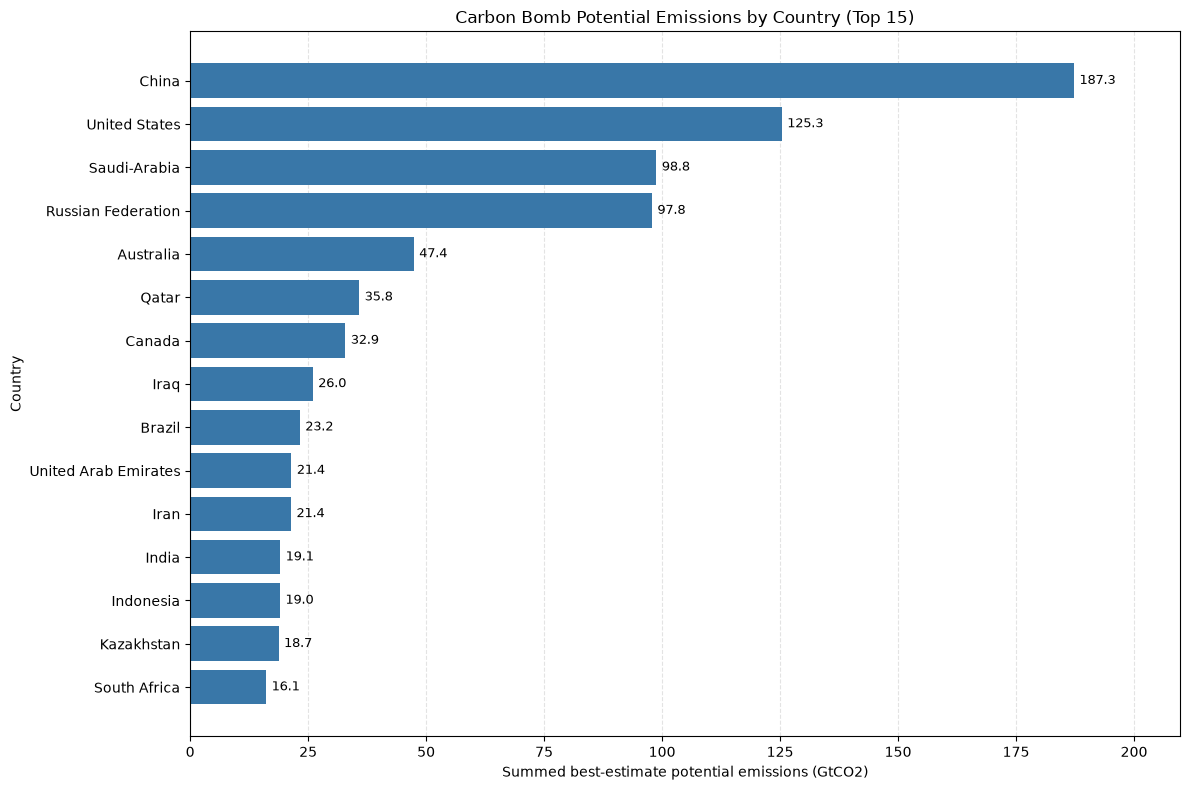

In [6]:
country_figure, country_axes, country_totals = plot_country_totals(
    dataset,
    top_n=15,
    output_path=project_root / "figures" / "carbon_bombs_by_country.png",
)
display(country_totals)
display(country_figure)

## Task 6 - Compare cumulative potential emissions by fuel type

The second summary groups the same project-level best estimates by fuel. Bar labels show the total in GtCO2, and the annotation above each bar shows how many projects are in that group. The counts help distinguish the total contribution of a fuel category from its average project size.

,fuel,total_best,project_count
0,Oil&Gas,566.493122,195
1,Coal,357.380444,230


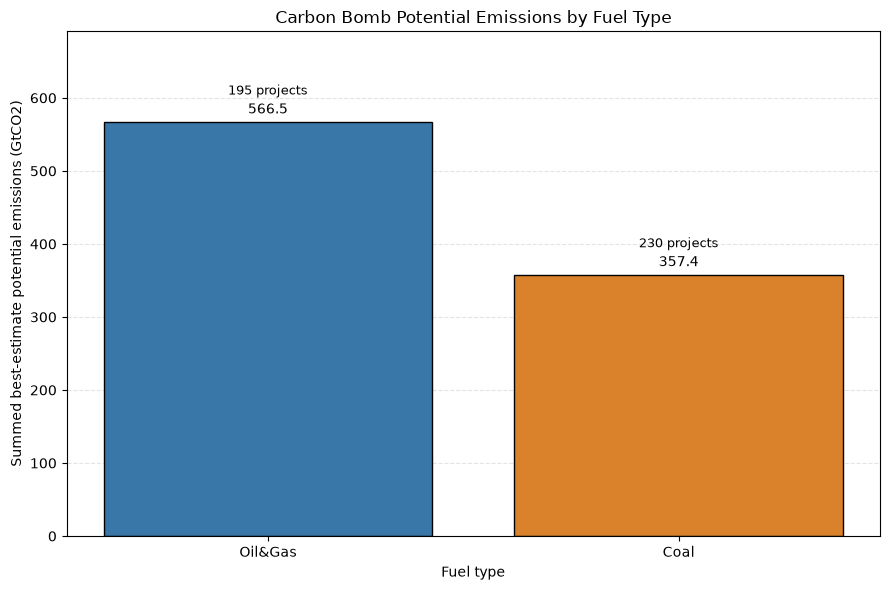

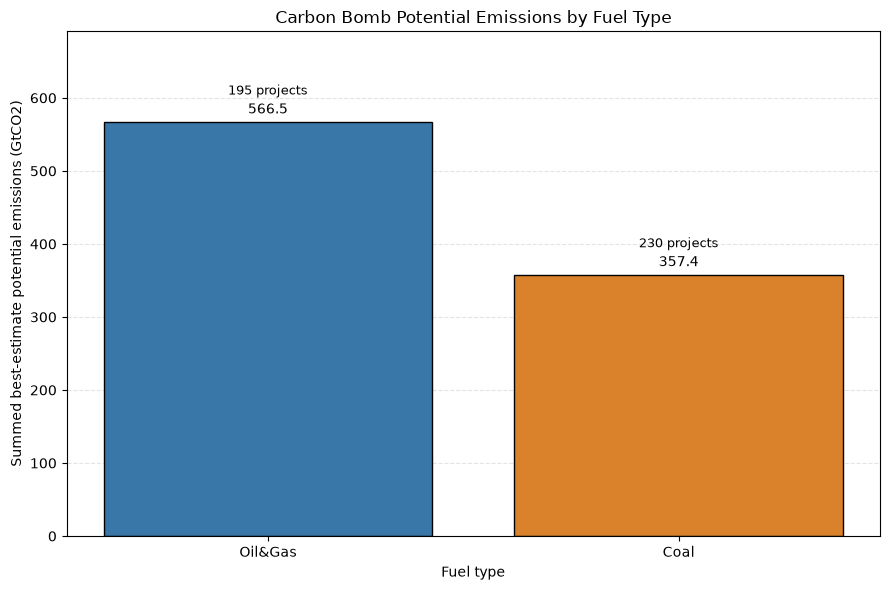

In [7]:
fuel_figure, fuel_axes, fuel_totals = plot_fuel_totals(
    dataset,
    output_path=project_root / "figures" / "carbon_bombs_by_fuel.png",
)
display(fuel_totals)
display(fuel_figure)

## Interpretation and report-ready summary

In the supplied 425-project dataset, Permian Delaware Tight has the largest best estimate (about 23.21 GtCO2), narrowly followed by Marcellus Shale (about 23.02 GtCO2). The top-20 plot shows that several of the largest individual projects are located in the United States and that the list includes both coal and oil-and-gas projects. The error bars show that estimates have project-specific uncertainty ranges.

For the country-level summary, China has the largest summed best estimate (about 187.26 GtCO2), followed by the United States (about 125.34 GtCO2), Saudi Arabia (about 98.77 GtCO2), and the Russian Federation (about 97.83 GtCO2). These totals describe the projects included in this dataset; they should not be read as emissions already released or as emissions attributed to a country's consumers.

By fuel type, oil and gas sum to about 566.49 GtCO2 across 195 projects, while coal sums to about 357.38 GtCO2 across 230 projects. Thus oil and gas have the larger cumulative best estimate in this dataset even though coal has more listed projects. This comparison is descriptive: the plotted totals sum central estimates only and do not combine each project's low/high range into a national or fuel-level confidence interval.

All numbers in this paragraph refer to the current saved dataset. Re-run the cells after updating the data, and refresh this interpretation if the underlying project list or estimates change.